In [1]:
import os
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
import time

In [2]:
LR = 0.001

transform = transforms.Compose([
            transforms.ToTensor(),  # Convert images to PyTorch tensors
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Normalize images
        ])

In [3]:
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, transform=transform, download=True)

In [4]:
test_dataset = torchvision.datasets.CIFAR10(root='../data', train=False, transform=transform, download=True)

In [5]:
# Define data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [6]:
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

<class 'torch.Tensor'>
frog


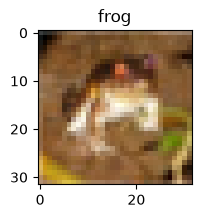

In [7]:
image, label = train_dataset[0]

print(type(image))   # <class 'PIL.Image.Image'>
print(classes[label])     # e.g. 6 for "frog"


plt.figure(figsize=(15, 2))

image, label = train_dataset[0]

# Undo normalization: (x * std) + mean
unnorm = image * 0.5 + 0.5   # since mean=0.5, std=0.5
plt.imshow(unnorm.permute(1, 2, 0))
plt.title(classes[label])
plt.show()

In [9]:

class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()

        # First convolutional layer: input channels=3 (RGB), output channels=32, kernel size=3x3, padding=1 to
        # preserve size
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)

        # Second convolutional layer: takes 32 feature maps, outputs 64, kernel size=3x3, padding=1
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        # Max pooling layer: reduces spatial dimensions by factor of 2
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layer: after two pools, CIFAR-10 (32x32) → 8x8 feature maps
        # 64 feature maps of size 8x8 = 64*8*8 = 4096 inputs
        self.fc1 = nn.Linear(64 * 8 * 8, 128)

        # Output layer: 128 → number of classes (10 for CIFAR-10)
        self.fc2 = nn.Linear(128, num_classes)

        # Folder path to save model checkpoints
        self.model_folder_path = './model'

    def forward(self, x):
        # Apply first convolution + ReLU, then pooling → output shape (32, 16, 16)
        x = self.pool(F.relu(self.conv1(x)))

        # Apply second convolution + ReLU, then pooling → output shape (64, 8, 8)
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten the tensor into a vector: (batch_size, 64*8*8 = 4096)
        x = x.view(x.size(0), -1)

        # Fully connected layer with ReLU → (batch_size, 128)
        x = F.relu(self.fc1(x))

        # Final fully connected layer (logits, not softmax) → (batch_size, num_classes)
        x = self.fc2(x)

        return x  # raw scores, CrossEntropyLoss will handle softmax internally

In [10]:
# 1. Automatically pick the best available hardware accelerator
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

# Move the model to the selected device
model = SimpleCNN(len(train_dataset.classes)).to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

best_val_loss = float('inf')
num_epochs = 20  

# 2. Record the starting time right before training begins
start_time = time.time()

for epoch in range(num_epochs):
    model.train()  
    running_loss = 0.0

    for images, labels in train_loader:
        # 3. Move data to the selected device (GPU/MPS/CPU)
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()  
        outputs = model(images)  
        loss = loss_function(outputs, labels)  
        loss.backward()  
        optimizer.step()  

        running_loss += loss.item()

    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader)}')

# 4. Record the ending time and calculate the duration
end_time = time.time()
total_training_time = end_time - start_time

print(f"\nTraining completed in: {total_training_time:.2f} seconds")


Using device: mps
Epoch [1/20], Loss: 1.260902985920909
Epoch [2/20], Loss: 0.8941741735219803
Epoch [3/20], Loss: 0.7312894930499376
Epoch [4/20], Loss: 0.6056688802408546
Epoch [5/20], Loss: 0.4926866093222636
Epoch [6/20], Loss: 0.3910007598122876
Epoch [7/20], Loss: 0.30077043105863027
Epoch [8/20], Loss: 0.22966644310190445
Epoch [9/20], Loss: 0.17792901414150392
Epoch [10/20], Loss: 0.1400894425113424
Epoch [11/20], Loss: 0.12107496219195583
Epoch [12/20], Loss: 0.09992812880730793
Epoch [13/20], Loss: 0.09406828939951498
Epoch [14/20], Loss: 0.08359997420615242
Epoch [15/20], Loss: 0.08340046427208782
Epoch [16/20], Loss: 0.06689016055960002
Epoch [17/20], Loss: 0.07428236727274165
Epoch [18/20], Loss: 0.07098674702911158
Epoch [19/20], Loss: 0.06459830205813298
Epoch [20/20], Loss: 0.05872573279920547

Training completed in: 71.06 seconds


In [12]:
model.eval()  # Set the model to evaluation mode
test_loss = 0.0
correct = 0

# 1. Record the starting time right before evaluation begins
eval_start_time = time.time()

with torch.no_grad():
    for images, labels in test_loader:
        # 2. Move data to the selected device (GPU/MPS/CPU)
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = loss_function(outputs, labels)
        test_loss += loss.item()
        
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()

test_loss /= len(test_loader)
accuracy = 100 * correct / len(test_loader.dataset)

# 3. Record the ending time and calculate the duration
eval_end_time = time.time()
total_eval_time = eval_end_time - eval_start_time

print(f'Test Loss: {test_loss:.4f}, Accuracy: {accuracy:.2f}%')
print(f'Evaluation completed in: {total_eval_time:.2f} seconds')

Test Loss: 2.3271, Accuracy: 70.71%
Evaluation completed in: 0.68 seconds


In [13]:
torch.save(model.state_dict(), "model_ccn_gpu.pth")

In [14]:
trained_model = SimpleCNN(len(train_dataset.classes))
trained_model.load_state_dict(torch.load("model_ccn_gpu.pth"))

<All keys matched successfully>

In [15]:
from PIL import Image
import torch.nn.functional as F


new_transform = transforms.Compose([
            transforms.Resize((32, 32)),
            transforms.ToTensor(),  # Convert images to PyTorch tensors
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Normalize images
        ])



In [17]:
image_path = 'app_img/uk9.jpg'
image = Image.open(image_path)
image = new_transform(image)
image = image.unsqueeze(0)  # Add a batch dimension

# 1. Ensure the trained model is on the correct device
trained_model = trained_model.to(device)
trained_model.eval()  # Set the model to evaluation mode

# 2. Start the inference timer
inference_start_time = time.time()

with torch.no_grad():
    # 3. Move data to the selected device
    images = image.to(device)
    output = trained_model(images)
    
    # Apply softmax to get the probabilities
    probabilities = F.softmax(output, dim=1)
    _, predicted = torch.max(output, 1)

    index = predicted.item()
    predicted_label = classes[index]
    predicted_probability = probabilities[0][index].item()

# 4. Stop the inference timer
inference_end_time = time.time()
inference_duration = (inference_end_time - inference_start_time) * 1000 # Convert to milliseconds

print(f'Predicted Label: {predicted_label}')
print(f'Probability of Prediction: {predicted_probability * 100:.2f}%')
# print(f'Inference completed in: {inference_duration:.2f} ms')

Predicted Label: deer
Probability of Prediction: 98.59%


In [18]:
image_path = 'app_img/we3.webp'
image = Image.open(image_path)
image = new_transform(image)
image = image.unsqueeze(0)  # Add a batch dimension

# 1. Ensure the trained model is on the correct device
trained_model = trained_model.to(device)
trained_model.eval()  # Set the model to evaluation mode

# 2. Start the inference timer
inference_start_time = time.time()

with torch.no_grad():
    # 3. Move data to the selected device
    images = image.to(device)
    output = trained_model(images)
    
    # Apply softmax to get the probabilities
    probabilities = F.softmax(output, dim=1)
    _, predicted = torch.max(output, 1)

    index = predicted.item()
    predicted_label = classes[index]
    predicted_probability = probabilities[0][index].item()

# 4. Stop the inference timer
inference_end_time = time.time()
inference_duration = (inference_end_time - inference_start_time) * 1000 # Convert to milliseconds

print(f'Predicted Label: {predicted_label}')
print(f'Probability of Prediction: {predicted_probability * 100:.2f}%')

Predicted Label: bird
Probability of Prediction: 50.41%


In [15]:
image_path = 'app_img/uk2.jpg'
image = Image.open(image_path)
image = new_transform(image)
image = image.unsqueeze(0)  # Add a batch dimension

trained_model.eval()  # Set the model to evaluation mode
test_loss = 0.0
correct = 0

with torch.no_grad():
    # Move data to the GPU
    images = image.to(device)
    output = trained_model(images)
    # Apply softmax to get the probabilities
    probabilities = F.softmax(output, dim=1)
    _, predicted = torch.max(output, 1)

    index = predicted.item()
    predicted_label = classes[index]
    predicted_probability = probabilities[0][index].item()

    print(f'Predicted Label: {predicted_label}')
    print(f'Probability of Correct Prediction: {predicted_probability * 100:.2f}%')

Predicted Label: bird
Probability of Correct Prediction: 100.00%


In [27]:
image_path = 'app_img/uk9.jpg'
image = Image.open(image_path)
image = new_transform(image)
image = image.unsqueeze(0)  # Add a batch dimension

# 1. Ensure the trained model is on the correct device
trained_model = trained_model.to(device)
trained_model.eval()  # Set the model to evaluation mode

# 2. Start the inference timer
inference_start_time = time.time()

with torch.no_grad():
    # 3. Move data to the selected device
    images = image.to(device)
    output = trained_model(images)
    
    # Apply softmax to get the probabilities
    probabilities = F.softmax(output, dim=1)
    _, predicted = torch.max(output, 1)

    index = predicted.item()
    predicted_label = classes[index]
    predicted_probability = probabilities[0][index].item()

# 4. Stop the inference timer
inference_end_time = time.time()
inference_duration = (inference_end_time - inference_start_time) * 1000 # Convert to milliseconds

print(f'Predicted Label: {predicted_label}')
print(f'Probability of Prediction: {predicted_probability * 100:.2f}%')

Predicted Label: deer
Probability of Prediction: 98.59%


In [25]:
image_path = 'app_img/af1.avif'
image = Image.open(image_path)
image = new_transform(image)
image = image.unsqueeze(0)  # Add a batch dimension

trained_model.eval()  # Set the model to evaluation mode
test_loss = 0.0
correct = 0

with torch.no_grad():
    # Move data to the GPU
    images = image.to(device)
    output = trained_model(images)
    # Apply softmax to get the probabilities
    probabilities = F.softmax(output, dim=1)
    _, predicted = torch.max(output, 1)

    index = predicted.item()
    predicted_label = classes[index]
    predicted_probability = probabilities[0][index].item()

    print(f'Predicted Label: {predicted_label}')
    print(f'Probability of Correct Prediction: {predicted_probability * 100:.2f}%')

Predicted Label: horse
Probability of Correct Prediction: 61.54%


In [26]:
image_path = 'app_img/uk8.jpg'
image = Image.open(image_path)
image = new_transform(image)
image = image.unsqueeze(0)  # Add a batch dimension

trained_model.eval()  # Set the model to evaluation mode
test_loss = 0.0
correct = 0

with torch.no_grad():
    # Move data to the GPU
    images = image.to(device)
    output = trained_model(images)
    # Apply softmax to get the probabilities
    probabilities = F.softmax(output, dim=1)
    _, predicted = torch.max(output, 1)

    index = predicted.item()
    predicted_label = classes[index]
    predicted_probability = probabilities[0][index].item()

    print(f'Predicted Label: {predicted_label}')
    print(f'Probability of Correct Prediction: {predicted_probability * 100:.2f}%')

Predicted Label: car
Probability of Correct Prediction: 99.95%
